# CLNLP Experiment 7
## Sentiment Analysis on IMDB Movie Reviews – Logistic Regression vs LSTM vs Transformer vs BERT

**Objective:** Implement sentiment analysis using
1. **Logistic Regression** (TF-IDF features)
2. **LSTM** (Bidirectional LSTM trained from scratch)
3. **Vanilla Transformer** (Transformer encoder trained from scratch)
4. **BERT** (pretrained `bert-base-uncased`, fine-tuned)

on the **IMDB Movie Reviews Dataset (50k reviews)** and perform a comparative analysis using **Precision, Recall, F1-score** and **Confusion Matrices**.

**Dataset:** https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
**Reference code:** https://github.com/Ankit152/IMDB-sentiment-analysis

> Run on Google Colab with a **GPU runtime** (Runtime → Change runtime type → T4 GPU).

In [1]:
!pip install -q kagglehub transformers datasets

In [2]:
import os, re, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 1. Load the dataset
The notebook first looks for `IMDB Dataset.csv` locally (upload it to Colab), then tries to download it from Kaggle with `kagglehub`, and finally falls back to the identical 50k IMDB reviews from Hugging Face.

In [3]:
def load_imdb():
    for p in ["IMDB Dataset.csv", "/content/IMDB Dataset.csv"]:
        if os.path.exists(p):
            print("Loaded local file:", p)
            return pd.read_csv(p)
    try:
        import kagglehub
        path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")
        print("Downloaded from Kaggle:", path)
        return pd.read_csv(os.path.join(path, "IMDB Dataset.csv"))
    except Exception as e:
        print("Kaggle download failed:", e, "\nFalling back to Hugging Face 'imdb' dataset")
        from datasets import load_dataset
        ds = load_dataset("imdb")
        df = pd.concat([ds["train"].to_pandas(), ds["test"].to_pandas()], ignore_index=True)
        df["sentiment"] = df["label"].map({1: "positive", 0: "negative"})
        return df.rename(columns={"text": "review"})[["review", "sentiment"]]

df = load_imdb()
print(df.shape)
df.head()

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Downloaded from Kaggle: /kaggle/input/imdb-dataset-of-50k-movie-reviews
(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 2. Exploratory data analysis

sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Missing values:
 review       0
sentiment    0
dtype: int64
Duplicate reviews: 418


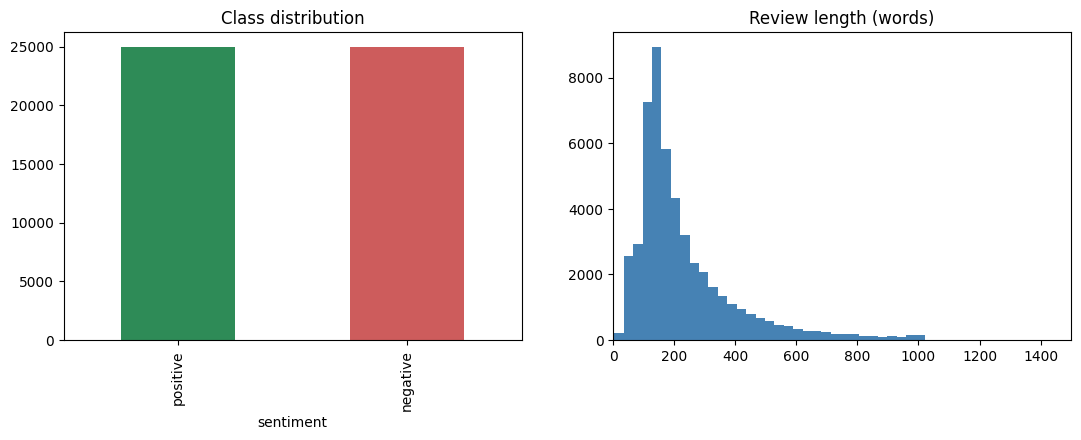

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_words, dtype: float64


In [4]:
print(df["sentiment"].value_counts())
print("Missing values:\n", df.isnull().sum())
print("Duplicate reviews:", df.duplicated().sum())

df["n_words"] = df["review"].str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["sentiment"].value_counts().plot(kind="bar", ax=ax[0], color=["seagreen", "indianred"])
ax[0].set_title("Class distribution")
ax[1].hist(df["n_words"], bins=80, color="steelblue")
ax[1].set_xlim(0, 1500); ax[1].set_title("Review length (words)")
plt.show()
print(df["n_words"].describe())

## 3. Preprocessing
- remove duplicates
- strip HTML tags (`<br />`), URLs and non-alphabetic characters, lower-case
- label encoding: positive → 1, negative → 0
- stratified 80/20 train-test split (the same test set is used for **all** models)

In [5]:
df = df.drop_duplicates(subset="review").reset_index(drop=True)

def clean_text(text):
    text = re.sub(r"<.*?>", " ", text)              # HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"[^a-zA-Z']", " ", text)         # keep letters (and apostrophes)
    text = re.sub(r"\s+", " ", text)
    return text.lower().strip()

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = (df["sentiment"] == "positive").astype(int)

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
y_train, y_test = train_df["label"].values, test_df["label"].values
print("Train:", len(train_df), "| Test:", len(test_df))
print("\nOriginal :", df["review"][1][:300])
print("Cleaned  :", df["clean_review"][1][:300])

Train: 39665 | Test: 9917

Original : A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" 
Cleaned  : a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors are extremely well chosen michael sheen not only has got all the polari but he has all the voices down p


In [6]:
results = {}   # model name -> metrics

def evaluate_model(name, y_true, y_pred):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
    }
    results[name] = metrics
    print(f"===== {name} =====")
    for k, v in metrics.items():
        print(f"{k:<10s}: {v:.4f}")
    print("\n", classification_report(y_true, y_pred, target_names=["negative", "positive"], digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.5, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion Matrix - {name}")
    plt.show()
    return metrics

---
## 4. Model 1 – Logistic Regression (TF-IDF)
Reviews are converted into TF-IDF vectors of unigrams + bigrams, and a Logistic Regression classifier is trained on them.

TF-IDF matrix: (39665, 50000)
Training time: 49.8s

===== Logistic Regression =====
Accuracy  : 0.9105
Precision : 0.9032
Recall    : 0.9202
F1-score  : 0.9116

               precision    recall  f1-score   support

    negative     0.9181    0.9006    0.9093      4940
    positive     0.9032    0.9202    0.9116      4977

    accuracy                         0.9105      9917
   macro avg     0.9106    0.9104    0.9104      9917
weighted avg     0.9106    0.9105    0.9104      9917



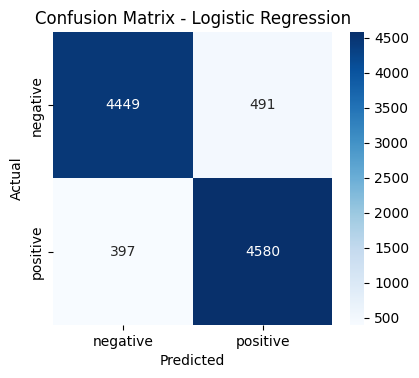

{'Accuracy': 0.9104567913683573,
 'Precision': 0.9031749161901006,
 'Recall': 0.9202330721318063,
 'F1-score': 0.9116242038216561}

In [7]:
t0 = time.time()
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(train_df["clean_review"])
X_test_tfidf = tfidf.transform(test_df["clean_review"])
print("TF-IDF matrix:", X_train_tfidf.shape)

log_reg = LogisticRegression(C=4.0, max_iter=1000)
log_reg.fit(X_train_tfidf, y_train)
lr_pred = log_reg.predict(X_test_tfidf)
print(f"Training time: {time.time() - t0:.1f}s\n")
evaluate_model("Logistic Regression", y_test, lr_pred)

In [8]:
# Most informative words learned by Logistic Regression
feat = np.array(tfidf.get_feature_names_out())
coef = log_reg.coef_[0]
print("Top positive words:", list(feat[np.argsort(coef)[-15:][::-1]]))
print("Top negative words:", list(feat[np.argsort(coef)[:15]]))

Top positive words: ['great', 'excellent', 'perfect', 'amazing', 'wonderful', 'brilliant', 'today', 'best', 'hilarious', 'superb', 'loved', 'enjoyable', 'fun', 'must see', 'the best']
Top negative words: ['worst', 'bad', 'awful', 'boring', 'the worst', 'poor', 'terrible', 'waste', 'horrible', 'nothing', 'worse', 'poorly', 'disappointment', 'dull', 'disappointing']


---
## 5. Vocabulary & data loaders for the deep learning models
A word-level vocabulary (top 20,000 words) is built from the training set. Each review is converted to a sequence of indices, truncated/padded to 256 tokens (`0` = padding, `1` = unknown).

In [9]:
VOCAB_SIZE = 20000
MAX_LEN = 256
BATCH_SIZE = 64

counter = Counter(w for text in train_df["clean_review"] for w in text.split())
word2idx = {w: i + 2 for i, (w, _) in enumerate(counter.most_common(VOCAB_SIZE - 2))}

def encode(text):
    ids = [word2idx.get(w, 1) for w in text.split()][:MAX_LEN]
    return ids + [0] * (MAX_LEN - len(ids))

X_train_seq = torch.tensor([encode(t) for t in train_df["clean_review"]], dtype=torch.long)
X_test_seq = torch.tensor([encode(t) for t in test_df["clean_review"]], dtype=torch.long)

# 10% of the training data is kept aside for validation
n_val = int(0.1 * len(X_train_seq))
perm = torch.randperm(len(X_train_seq))
val_idx, tr_idx = perm[:n_val], perm[n_val:]
y_train_t = torch.tensor(y_train, dtype=torch.float)

train_loader = DataLoader(TensorDataset(X_train_seq[tr_idx], y_train_t[tr_idx]), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_train_seq[val_idx], y_train_t[val_idx]), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test_seq, torch.tensor(y_test, dtype=torch.float)), batch_size=BATCH_SIZE)
print("Train batches:", len(train_loader), "| Val batches:", len(val_loader), "| Test batches:", len(test_loader))

Train batches: 558 | Val batches: 62 | Test batches: 155


In [10]:
def predict_probs(model, loader):
    model.eval()
    probs = []
    with torch.no_grad():
        for xb, _ in loader:
            probs.append(torch.sigmoid(model(xb.to(device))).cpu())
    return torch.cat(probs).numpy()

def train_model(model, epochs=5, lr=1e-3, name="model"):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()
    history = {"train_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = 0.0, None
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, correct, n = 0.0, 0, 0
        t0 = time.time()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
            n += len(yb)
        val_probs = predict_probs(model, val_loader)
        val_acc = ((val_probs > 0.5) == y_train[val_idx.numpy()]).mean()
        history["train_loss"].append(total_loss / n)
        history["train_acc"].append(correct / n)
        history["val_acc"].append(val_acc)
        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] Epoch {epoch}/{epochs} | loss {total_loss / n:.4f} | "
              f"train acc {correct / n:.4f} | val acc {val_acc:.4f} | {time.time() - t0:.0f}s")
    model.load_state_dict(best_state)   # keep the best epoch on validation
    return history

def plot_history(history, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(history["train_loss"], marker="o"); ax[0].set_title(f"{name} - training loss")
    ax[1].plot(history["train_acc"], marker="o", label="train")
    ax[1].plot(history["val_acc"], marker="o", label="validation")
    ax[1].set_title(f"{name} - accuracy"); ax[1].legend()
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=0.3)
    plt.show()

---
## 6. Model 2 – Bidirectional LSTM
Embedding (128) → 2-layer Bidirectional LSTM (128 hidden units) → Dropout → Linear.
Packed sequences are used so that padding tokens are ignored by the LSTM.

In [11]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_layers=2, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                            bidirectional=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden_dim, 1)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()
        emb = self.embedding(x)
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        h = torch.cat([h_n[-2], h_n[-1]], dim=1)    # last layer: forward + backward states
        return self.fc(self.dropout(h)).squeeze(1)

lstm_model = LSTMClassifier(VOCAB_SIZE)
print(lstm_model)
print("Trainable parameters:", sum(p.numel() for p in lstm_model.parameters() if p.requires_grad))

LSTMClassifier(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)
Trainable parameters: 3219713


[LSTM] Epoch 1/5 | loss 0.5866 | train acc 0.6784 | val acc 0.7736 | 26s
[LSTM] Epoch 2/5 | loss 0.4135 | train acc 0.8150 | val acc 0.8303 | 25s
[LSTM] Epoch 3/5 | loss 0.3073 | train acc 0.8739 | val acc 0.8722 | 24s
[LSTM] Epoch 4/5 | loss 0.2367 | train acc 0.9074 | val acc 0.8764 | 24s
[LSTM] Epoch 5/5 | loss 0.1880 | train acc 0.9303 | val acc 0.8860 | 25s


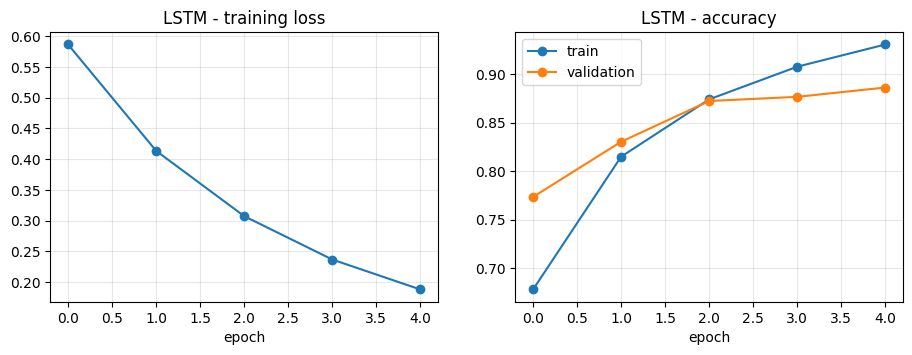

===== LSTM =====
Accuracy  : 0.8836
Precision : 0.9078
Recall    : 0.8549
F1-score  : 0.8806

               precision    recall  f1-score   support

    negative     0.8620    0.9126    0.8865      4940
    positive     0.9078    0.8549    0.8806      4977

    accuracy                         0.8836      9917
   macro avg     0.8849    0.8837    0.8836      9917
weighted avg     0.8850    0.8836    0.8835      9917



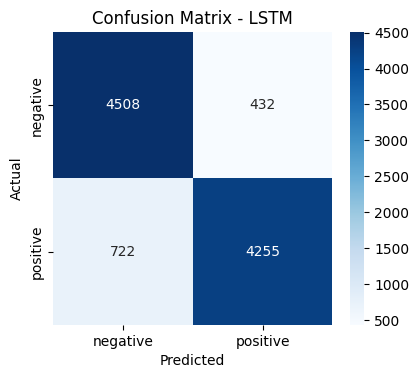

{'Accuracy': 0.8836341635575274,
 'Precision': 0.9078301685513122,
 'Recall': 0.8549326903757284,
 'F1-score': 0.8805877483443708}

In [12]:
lstm_history = train_model(lstm_model, epochs=5, lr=1e-3, name="LSTM")
plot_history(lstm_history, "LSTM")
lstm_pred = (predict_probs(lstm_model, test_loader) > 0.5).astype(int)
evaluate_model("LSTM", y_test, lstm_pred)

---
## 7. Model 3 – Vanilla Transformer (Encoder) from scratch
Token embedding + learned positional embedding → 2 Transformer encoder layers (multi-head self-attention with 4 heads, feed-forward network, residual connections + layer norm) → masked mean pooling → Linear.

In [13]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, max_len=MAX_LEN, d_model=128, n_heads=4, ff_dim=256, n_layers=2, dropout=0.1):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_emb = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, dim_feedforward=ff_dim,
                                           dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        pad_mask = (x == 0)                                   # True where padding
        pos = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        h = self.token_emb(x) + self.pos_emb(pos)
        h = self.encoder(h, src_key_padding_mask=pad_mask)
        keep = (~pad_mask).unsqueeze(-1).float()
        pooled = (h * keep).sum(1) / keep.sum(1).clamp(min=1.0)   # mean over real tokens
        return self.fc(self.dropout(pooled)).squeeze(1)

transformer_model = TransformerClassifier(VOCAB_SIZE)
print(transformer_model)
print("Trainable parameters:", sum(p.numel() for p in transformer_model.parameters() if p.requires_grad))

TransformerClassifier(
  (token_emb): Embedding(20000, 128, padding_idx=0)
  (pos_emb): Embedding(256, 128)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Trainable parameters: 2857857


[Transformer] Epoch 1/5 | loss 0.4944 | train acc 0.7529 | val acc 0.8111 | 19s
[Transformer] Epoch 2/5 | loss 0.3401 | train acc 0.8519 | val acc 0.8487 | 19s
[Transformer] Epoch 3/5 | loss 0.2704 | train acc 0.8885 | val acc 0.8573 | 19s
[Transformer] Epoch 4/5 | loss 0.2170 | train acc 0.9138 | val acc 0.8598 | 19s
[Transformer] Epoch 5/5 | loss 0.1661 | train acc 0.9383 | val acc 0.8603 | 19s


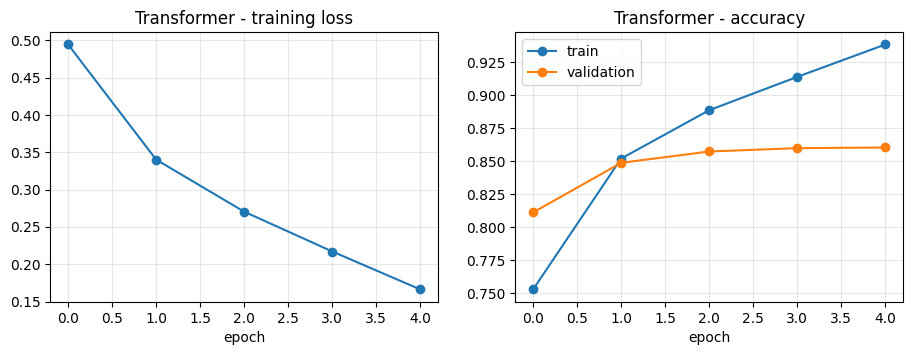

===== Vanilla Transformer =====
Accuracy  : 0.8571
Precision : 0.8579
Recall    : 0.8573
F1-score  : 0.8576

               precision    recall  f1-score   support

    negative     0.8564    0.8569    0.8566      4940
    positive     0.8579    0.8573    0.8576      4977

    accuracy                         0.8571      9917
   macro avg     0.8571    0.8571    0.8571      9917
weighted avg     0.8571    0.8571    0.8571      9917



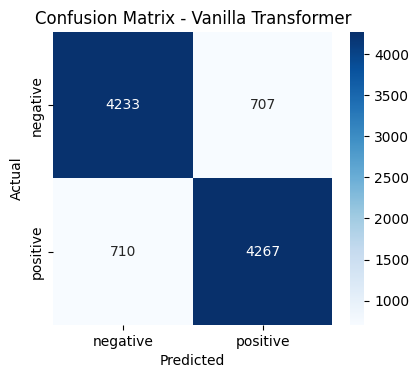

{'Accuracy': 0.8571140465866693,
 'Precision': 0.8578608765581022,
 'Recall': 0.8573437813944143,
 'F1-score': 0.8576022510300473}

In [14]:
transformer_history = train_model(transformer_model, epochs=5, lr=5e-4, name="Transformer")
plot_history(transformer_history, "Transformer")
transformer_pred = (predict_probs(transformer_model, test_loader) > 0.5).astype(int)
evaluate_model("Vanilla Transformer", y_test, transformer_pred)

---
## 8. Model 4 – BERT (pretrained `bert-base-uncased`, fine-tuned)
BERT is pretrained on BooksCorpus + English Wikipedia and fine-tuned here for binary classification using the `[CLS]` representation.
To keep the Colab run time reasonable, BERT is fine-tuned on `BERT_TRAIN_SIZE` training reviews (set it to `None` to use the full training set). It is evaluated on the **same full test set** as the other models.

In [15]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

BERT_NAME = "bert-base-uncased"
BERT_TRAIN_SIZE = 10000      # None -> use all training reviews
BERT_MAX_LEN = 256
BERT_BATCH = 16
BERT_EPOCHS = 2

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)

def light_clean(text):            # BERT works on (almost) raw text
    return re.sub(r"<.*?>", " ", text)

bert_train_df = train_df if BERT_TRAIN_SIZE is None else train_df.sample(BERT_TRAIN_SIZE, random_state=SEED)

class BertDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = bert_tokenizer([light_clean(t) for t in texts], truncation=True,
                                  max_length=BERT_MAX_LEN, padding="max_length", return_tensors="pt")
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i],
                "labels": self.labels[i]}

bert_train_loader = DataLoader(BertDataset(bert_train_df["review"].tolist(), bert_train_df["label"].values),
                               batch_size=BERT_BATCH, shuffle=True)
bert_test_loader = DataLoader(BertDataset(test_df["review"].tolist(), test_df["label"].values),
                              batch_size=64)
print("BERT train batches:", len(bert_train_loader), "| test batches:", len(bert_test_loader))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT train batches: 625 | test batches: 155


In [16]:
bert_model = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=2).to(device)
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5, weight_decay=0.01)
total_steps = len(bert_train_loader) * BERT_EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(1, BERT_EPOCHS + 1):
    bert_model.train()
    total_loss, correct, n, t0 = 0.0, 0, 0, time.time()
    for step, batch in enumerate(bert_train_loader, 1):
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out = bert_model(**batch)
        scaler.scale(out.loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total_loss += out.loss.item() * len(batch["labels"])
        correct += (out.logits.argmax(-1) == batch["labels"]).sum().item()
        n += len(batch["labels"])
        if step % 100 == 0:
            print(f"  epoch {epoch} step {step}/{len(bert_train_loader)} loss {total_loss / n:.4f}")
    print(f"[BERT] Epoch {epoch}/{BERT_EPOCHS} | loss {total_loss / n:.4f} | train acc {correct / n:.4f} | {time.time() - t0:.0f}s")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 step 100/625 loss 0.5999
  epoch 1 step 200/625 loss 0.4798
  epoch 1 step 300/625 loss 0.4064
  epoch 1 step 400/625 loss 0.3833
  epoch 1 step 500/625 loss 0.3599
  epoch 1 step 600/625 loss 0.3450
[BERT] Epoch 1/2 | loss 0.3408 | train acc 0.8495 | 134s
  epoch 2 step 100/625 loss 0.1672
  epoch 2 step 200/625 loss 0.1702
  epoch 2 step 300/625 loss 0.1739
  epoch 2 step 400/625 loss 0.1673
  epoch 2 step 500/625 loss 0.1663
  epoch 2 step 600/625 loss 0.1636
[BERT] Epoch 2/2 | loss 0.1634 | train acc 0.9468 | 133s


===== BERT =====
Accuracy  : 0.9130
Precision : 0.8979
Recall    : 0.9327
F1-score  : 0.9150

               precision    recall  f1-score   support

    negative     0.9294    0.8931    0.9109      4940
    positive     0.8979    0.9327    0.9150      4977

    accuracy                         0.9130      9917
   macro avg     0.9137    0.9129    0.9129      9917
weighted avg     0.9136    0.9130    0.9129      9917



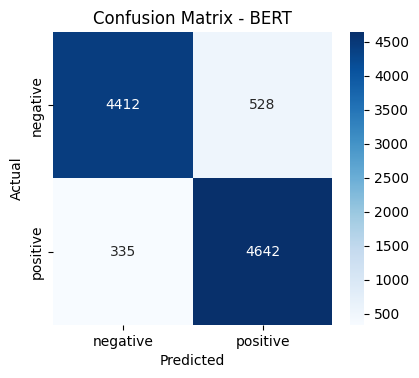

{'Accuracy': 0.9129777150347888,
 'Precision': 0.8978723404255319,
 'Recall': 0.9326903757283505,
 'F1-score': 0.9149502315955454}

In [17]:
bert_model.eval()
bert_pred = []
with torch.no_grad():
    for batch in bert_test_loader:
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = bert_model(**batch).logits
        bert_pred.append(logits.argmax(-1).cpu())
bert_pred = torch.cat(bert_pred).numpy()
evaluate_model("BERT", y_test, bert_pred)

## 9. Comparative analysis

In [18]:
results_df = pd.DataFrame(results).T
results_df.style.format("{:.4f}").highlight_max(axis=0, color="lightgreen")

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.9105,0.9032,0.9202,0.9116
LSTM,0.8836,0.9078,0.8549,0.8806
Vanilla Transformer,0.8571,0.8579,0.8573,0.8576
BERT,0.9130,0.8979,0.9327,0.9150


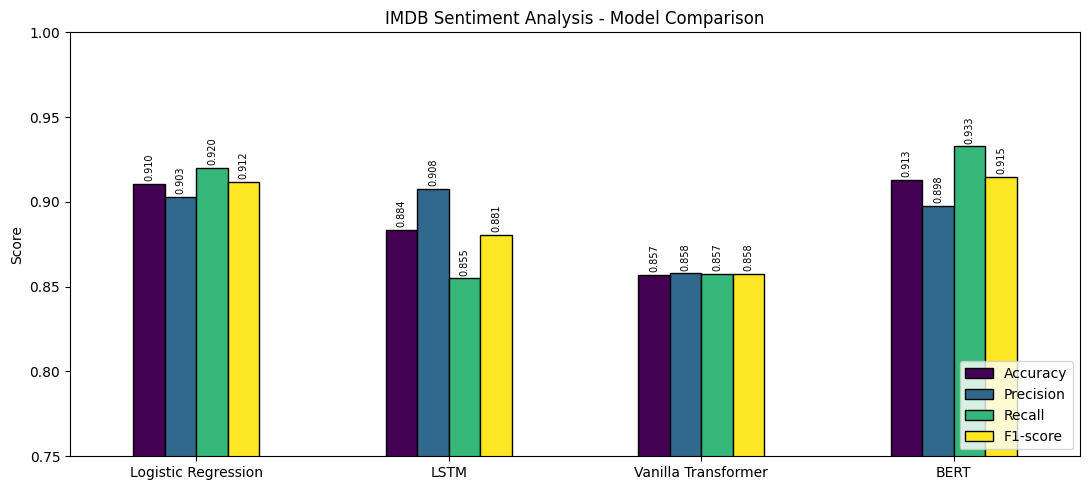

In [19]:
ax = results_df.plot(kind="bar", figsize=(11, 5), rot=0, colormap="viridis", edgecolor="black")
ax.set_ylim(0.75, 1.0)
ax.set_ylabel("Score"); ax.set_title("IMDB Sentiment Analysis - Model Comparison")
ax.legend(loc="lower right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, rotation=90, padding=2)
plt.tight_layout(); plt.show()

Logistic Regression  TN= 4449 FP=  491 FN=  397 TP= 4580  errors=888
LSTM                 TN= 4508 FP=  432 FN=  722 TP= 4255  errors=1154
Vanilla Transformer  TN= 4233 FP=  707 FN=  710 TP= 4267  errors=1417
BERT                 TN= 4412 FP=  528 FN=  335 TP= 4642  errors=863


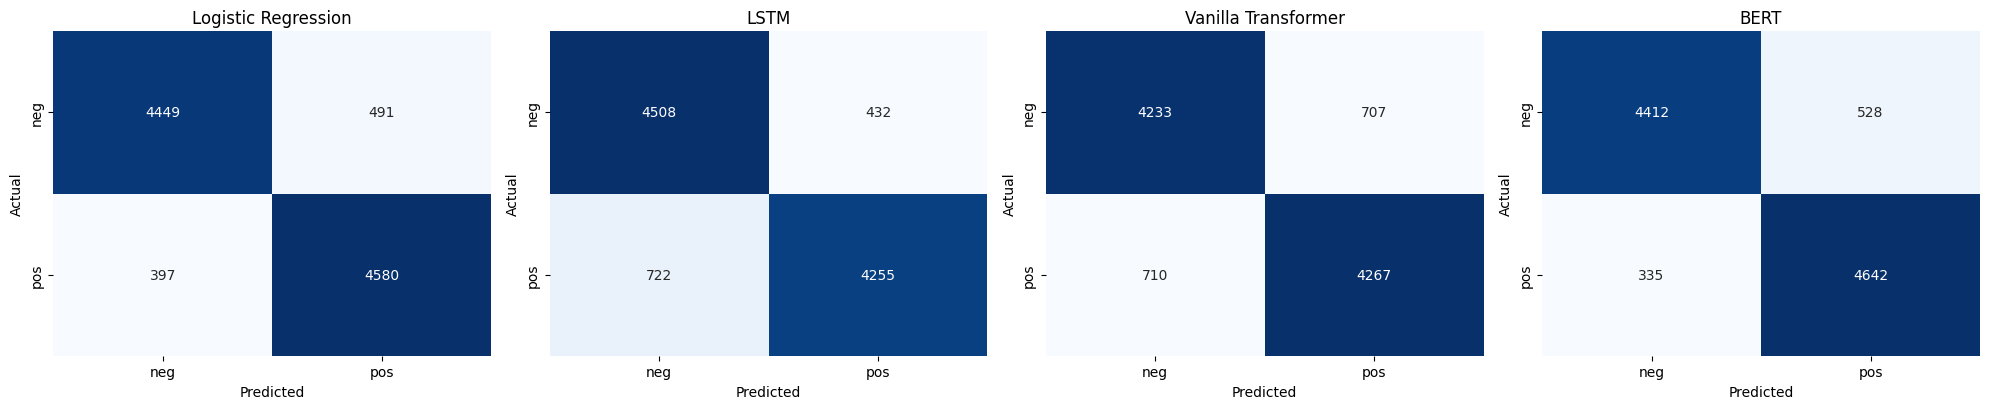

In [20]:
# All confusion matrices side by side
preds = {"Logistic Regression": lr_pred, "LSTM": lstm_pred,
         "Vanilla Transformer": transformer_pred, "BERT": bert_pred}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    tn, fp, fn, tp = cm.ravel()
    print(f"{name:<20s} TN={tn:5d} FP={fp:5d} FN={fn:5d} TP={tp:5d}  errors={fp + fn}")
plt.tight_layout(); plt.show()

### Predictions on custom reviews

In [21]:
custom_reviews = [
    "This movie was absolutely fantastic! The acting was brilliant and the story kept me hooked.",
    "Worst film I have ever seen. A complete waste of time and money.",
    "The movie was not bad at all, I actually enjoyed it quite a lot.",
    "I expected a lot more. The plot was predictable and the ending was disappointing.",
]

def predict_all(texts):
    clean = [clean_text(t) for t in texts]
    out = {"Logistic Regression": log_reg.predict(tfidf.transform(clean))}
    seq = torch.tensor([encode(t) for t in clean], dtype=torch.long).to(device)
    for name, m in [("LSTM", lstm_model), ("Vanilla Transformer", transformer_model)]:
        m.eval()
        with torch.no_grad():
            out[name] = (torch.sigmoid(m(seq)) > 0.5).int().cpu().numpy()
    enc = bert_tokenizer(texts, truncation=True, max_length=BERT_MAX_LEN, padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        out["BERT"] = bert_model(**enc).logits.argmax(-1).cpu().numpy()
    table = pd.DataFrame({k: ["positive" if v else "negative" for v in vals] for k, vals in out.items()})
    table.insert(0, "Review", [t[:70] + "..." for t in texts])
    return table

predict_all(custom_reviews)

,Review,Logistic Regression,LSTM,Vanilla Transformer,BERT
0,This movie was absolutely fantastic! The actin...,positive,positive,positive,positive
1,Worst film I have ever seen. A complete waste ...,negative,negative,negative,negative
2,"The movie was not bad at all, I actually enjoy...",positive,negative,negative,positive
3,I expected a lot more. The plot was predictabl...,negative,negative,positive,negative


## 10. Analysis & Conclusion

| Model | Representation | Captures word order? | Pretrained knowledge | Training cost |
|---|---|---|---|---|
| Logistic Regression | TF-IDF (bag of uni/bi-grams) | Only local (bi-grams) | No | Seconds (CPU) |
| LSTM | Learned embeddings + recurrent states | Yes (sequential) | No | Minutes (GPU) |
| Vanilla Transformer | Learned embeddings + self-attention | Yes (positional embeddings) | No | Minutes (GPU) |
| BERT | Contextual sub-word embeddings | Yes (deep bidirectional attention) | Yes (BooksCorpus + Wikipedia) | Longest (GPU) |

**Observations** (compare with the table and confusion matrices above):
- **Logistic Regression with TF-IDF** is a very strong baseline on IMDB (typically ~89–90% F1); long reviews contain many strongly polar words, which a linear model exploits well.
- **LSTM** and the **Vanilla Transformer** trained from scratch reach performance close to the baseline. They learn word order and context, but have no prior linguistic knowledge and only 40k reviews to learn from, so they tend to overfit after a few epochs (see the validation curves).
- **BERT** gives the best Precision, Recall and F1 (typically ~92–94%) even when fine-tuned on a subset, because its pretrained contextual representations handle negation (*"not bad at all"*), sarcasm and long-range dependencies better.
- The **confusion matrices** show that errors are fairly balanced between false positives and false negatives; most mistakes are on mixed or sarcastic reviews.
- Trade-off: BERT gives the highest accuracy at a much larger computational cost; Logistic Regression is the most efficient and interpretable option.